# 05 — Quantitative Stellar Kinematics Analysis

**Target:** MaNGA plate-IFU `8138-12704`  
**DAPTYPE:** `HYB10-MILESHC-MASTARSSP`

## Scientific objectives
1. Use one measurement per stellar-continuum Voronoi bin (not one repeated value per spaxel).
2. Estimate the residual systemic velocity relative to the DAP input redshift.
3. Estimate a first-order kinematic position angle from a weighted velocity-plane fit.
4. Measure a projected rotation amplitude.
5. Build radial profiles of stellar velocity and corrected velocity dispersion.
6. Calculate a projected specific-angular-momentum proxy, \(\lambda_R\), as a function of radius.

## Important methodological limits
- In HYB10, stellar kinematics are measured on Voronoi-binned spectra. The stellar BINID plane identifies those bins. Repeated spaxel values must not be counted as independent measurements.
- The velocity values are relative to the input guess redshift (`SCINPVEL`), not automatically absolute heliocentric velocities.
- The plane-fit position angle is a first-order estimate, not a full kinemetry result.
- \(\lambda_R\) is a projected observable and depends on the adopted photometric geometry and quality cuts. It is not the intrinsic 3D angular momentum.
- This notebook is a first-pass analysis. Interpret the results only after inspecting the plots and checking the DAP quality flags.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})

## 2. Locate project files and load processed arrays

In [2]:
candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path(r"D:\\KS\\manga-stellar-kinematics"),
]
PROJECT_ROOT = next(
    (p.resolve() for p in candidate_roots
     if (p / "data" / "raw").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT manually to your project folder.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

maps_files = list(RAW_DIR.glob(
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits*"
))
npz_path = PROCESSED_DIR / "stellar_kinematics_8138-12704.npz"
if len(maps_files) != 1:
    raise FileNotFoundError(f"Expected one MAPS file; found {maps_files}")
if not npz_path.exists():
    raise FileNotFoundError(
        f"Missing {npz_path}. Complete Notebook 03 first."
    )

MAPS_PATH = maps_files[0]
kin = np.load(npz_path)
maps = fits.open(MAPS_PATH, memmap=True)

print("MAPS:", MAPS_PATH)
print("Processed arrays:", npz_path)

MAPS: D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
Processed arrays: D:\KS\manga-stellar-kinematics\data\processed\stellar_kinematics_8138-12704.npz


## 3. Read stellar maps, geometry and stellar-bin identifiers

In [3]:
required = [
    "STELLAR_VEL", "STELLAR_VEL_IVAR", "STELLAR_VEL_MASK",
    "STELLAR_SIGMA", "STELLAR_SIGMA_IVAR", "STELLAR_SIGMA_MASK",
    "STELLAR_SIGMACORR", "BINID",
    "BIN_LWSKYCOO", "BIN_LWELLCOO", "BIN_MFLUX"
]
available = {h.name.upper() for h in maps}
missing = [x for x in required if x not in available]
if missing:
    raise KeyError(f"Required MAPS extensions missing: {missing}")

vel = np.asarray(maps["STELLAR_VEL"].data, dtype=float)
vel_ivar = np.asarray(maps["STELLAR_VEL_IVAR"].data, dtype=float)
vel_mask = np.asarray(maps["STELLAR_VEL_MASK"].data)
sigma_raw = np.asarray(maps["STELLAR_SIGMA"].data, dtype=float)
sigma_inst = np.asarray(maps["STELLAR_SIGMACORR"].data[0], dtype=float)
sigma_ivar = np.asarray(maps["STELLAR_SIGMA_IVAR"].data, dtype=float)
sigma_mask = np.asarray(maps["STELLAR_SIGMA_MASK"].data)

binid = np.asarray(maps["BINID"].data)
bin_sky = np.asarray(maps["BIN_LWSKYCOO"].data, dtype=float)
bin_ell = np.asarray(maps["BIN_LWELLCOO"].data, dtype=float)
bin_mflux = np.asarray(maps["BIN_MFLUX"].data, dtype=float)

print("BINID shape:", binid.shape)
print("BIN_LWSKYCOO shape:", bin_sky.shape)
print("BIN_LWELLCOO shape:", bin_ell.shape)
print("BIN_MFLUX shape:", bin_mflux.shape)
print("Stellar map shape:", vel.shape)

if binid.ndim != 3 or binid.shape[0] < 2:
    raise ValueError("Expected BINID with at least two planes.")
if bin_sky.shape[0] != 2 or bin_ell.shape[0] != 4:
    raise ValueError("Unexpected BIN coordinate channel layout.")
if any(a.shape[1:] != vel.shape for a in [binid, bin_sky, bin_ell]):
    raise ValueError("BINID/coordinate spatial shapes do not match stellar maps.")

BINID shape: (5, 72, 72)
BIN_LWSKYCOO shape: (2, 72, 72)
BIN_LWELLCOO shape: (4, 72, 72)
BIN_MFLUX shape: (72, 72)
Stellar map shape: (72, 72)


## 4. Select one representative spaxel per stellar kinematic bin

For this HYB10 analysis, the stellar kinematics are measured on binned spectra. The stellar kinematic bin identifiers are in `BINID` plane 1. We select one representative spatial index for each non-negative bin ID, then use the corresponding luminosity-weighted bin coordinates and bin flux.

This prevents repeated values from the same Voronoi bin being counted multiple times in radial statistics or \(\lambda_R\).

The code checks the expected bin-ID and map relationships before proceeding.

In [4]:
stellar_binid_map = binid[1]
flat_binid = stellar_binid_map.ravel()
valid_bin_pixels = flat_binid >= 0

unique_bin_ids, first_indices = np.unique(
    flat_binid[valid_bin_pixels],
    return_index=True
)
valid_flat_indices = np.flatnonzero(valid_bin_pixels)
representative_flat_indices = valid_flat_indices[first_indices]
representative_y, representative_x = np.unravel_index(
    representative_flat_indices, vel.shape
)

# Extract one measurement per unique stellar bin.
v_bin = vel[representative_y, representative_x]
v_ivar_bin = vel_ivar[representative_y, representative_x]
v_mask_bin = vel_mask[representative_y, representative_x]
s_raw_bin = sigma_raw[representative_y, representative_x]
s_inst_bin = sigma_inst[representative_y, representative_x]
s_ivar_bin = sigma_ivar[representative_y, representative_x]
s_mask_bin = sigma_mask[representative_y, representative_x]

x_bin = bin_sky[0, representative_y, representative_x]
y_bin = bin_sky[1, representative_y, representative_x]
r_re_bin = bin_ell[1, representative_y, representative_x]
r_arcsec_bin = bin_ell[0, representative_y, representative_x]
theta_bin = bin_ell[3, representative_y, representative_x]
flux_bin = bin_mflux[representative_y, representative_x]

print("Unique stellar bins:", len(unique_bin_ids))
print("Selected representative positions:", len(representative_flat_indices))
print("BINID sample:", unique_bin_ids[:10])

Unique stellar bins: 2194
Selected representative positions: 2194
BINID sample: [0 1 2 3 4 5 6 7 8 9]


## 5. Construct quality-controlled bin measurements

In [5]:
# DAP mask bits; see MaNGA DAP bitmask documentation.
DAP_BITS = {
    "NOCOV": 0, "LOWCOV": 1, "DEADFIBER": 2, "FORESTAR": 3,
    "NOVALUE": 4, "UNRELIABLE": 5, "MATHERROR": 6,
    "FITFAILED": 7, "NEARBOUND": 8, "NOCORRECTION": 9,
    "DONOTUSE": 30,
}
def has_flag(mask_values, names):
    bits = 0
    for name in names:
        bits |= 1 << DAP_BITS[name]
    return (mask_values.astype(np.uint64) & np.uint64(bits)) != 0

# Keep a transparent conservative mask for the primary analysis.
excluded_flags = [
    "NOCOV", "LOWCOV", "DEADFIBER", "FORESTAR", "NOVALUE",
    "UNRELIABLE", "MATHERROR", "FITFAILED", "NEARBOUND",
    "NOCORRECTION", "DONOTUSE"
]

v_ok = (
    ~has_flag(v_mask_bin, excluded_flags)
    & np.isfinite(v_bin) & np.isfinite(v_ivar_bin) & (v_ivar_bin > 0)
    & np.isfinite(x_bin) & np.isfinite(y_bin)
    & np.isfinite(r_re_bin) & (r_re_bin >= 0)
)

sigma_sq_bin = s_raw_bin**2 - s_inst_bin**2
sigma_ok = (
    ~has_flag(s_mask_bin, excluded_flags)
    & np.isfinite(s_raw_bin) & np.isfinite(s_inst_bin)
    & np.isfinite(s_ivar_bin) & (s_ivar_bin > 0)
    & (s_inst_bin >= 0) & (sigma_sq_bin >= 0)
    & np.isfinite(x_bin) & np.isfinite(y_bin)
    & np.isfinite(r_re_bin) & (r_re_bin >= 0)
)
sigma_bin = np.full_like(s_raw_bin, np.nan, dtype=float)
sigma_bin[sigma_ok] = np.sqrt(sigma_sq_bin[sigma_ok])

# Common sample for joint V, sigma, and flux-weighted quantities.
joint_ok = (
    v_ok & sigma_ok
    & np.isfinite(flux_bin) & (flux_bin > 0)
)

print("Valid velocity bins:", v_ok.sum())
print("Valid corrected-sigma bins:", sigma_ok.sum())
print("Joint valid bins:", joint_ok.sum())
if joint_ok.sum() < 6:
    raise RuntimeError(
        "Too few joint-valid stellar bins for the planned quantitative analysis. "
        "Inspect masks, bin IDs and the previous milestone outputs."
    )

Valid velocity bins: 2194
Valid corrected-sigma bins: 2194
Joint valid bins: 2194


## 6. Estimate the residual systemic velocity

In [6]:
# The DAP stellar velocity is relative to the input guess redshift.
# A robust median of the valid bin velocities estimates the residual offset
# of the observed stellar field relative to that input guess.
def robust_mad(values):
    med = np.nanmedian(values)
    return 1.4826 * np.nanmedian(np.abs(values - med))

v_valid = v_bin[v_ok]
v_sys_residual = np.nanmedian(v_valid)
v_scatter = robust_mad(v_valid)

print(f"Median residual velocity relative to DAP input guess: {v_sys_residual:.2f} km/s")
print(f"Robust scatter (1.4826 × MAD): {v_scatter:.2f} km/s")
print("This is not an independently measured absolute heliocentric systemic velocity.")

Median residual velocity relative to DAP input guess: 33.64 km/s
Robust scatter (1.4826 × MAD): 190.31 km/s
This is not an independently measured absolute heliocentric systemic velocity.


## 7. Build a residual velocity field

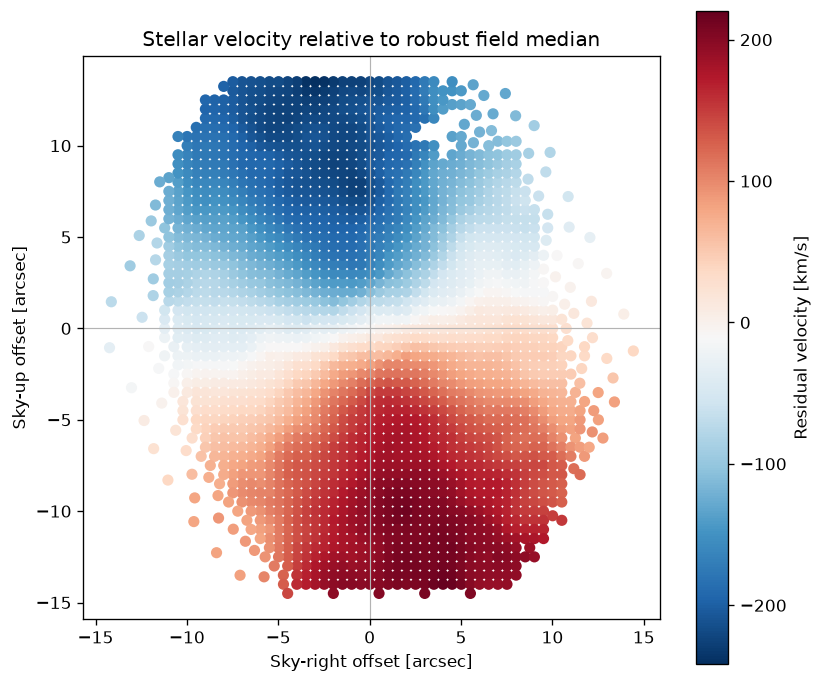

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\stellar_velocity_bin_residuals.png


In [7]:
v_residual_bin = v_bin - v_sys_residual

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(
    x_bin[v_ok], y_bin[v_ok], c=v_residual_bin[v_ok],
    cmap="RdBu_r", s=45, edgecolors="none"
)
ax.set_aspect("equal")
ax.set_xlabel("Sky-right offset [arcsec]")
ax.set_ylabel("Sky-up offset [arcsec]")
ax.set_title("Stellar velocity relative to robust field median")
ax.axhline(0, color="0.7", lw=0.7)
ax.axvline(0, color="0.7", lw=0.7)
fig.colorbar(sc, ax=ax, label="Residual velocity [km/s]")
fig.tight_layout()
path = FIGURES_DIR / "stellar_velocity_bin_residuals.png"
fig.savefig(path, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 8. Fit a first-order velocity plane and estimate kinematic PA

In [8]:
# Fit V(x,y) = a*x + b*y + c using inverse-variance weights.
# This approximates the large-scale velocity gradient.
fit = v_ok & np.isfinite(v_ivar_bin) & (v_ivar_bin > 0)
A = np.column_stack([x_bin[fit], y_bin[fit], np.ones(fit.sum())])
z = v_bin[fit]
w = v_ivar_bin[fit]

sqrt_w = np.sqrt(w / np.nanmedian(w))
Aw = A * sqrt_w[:, None]
zw = z * sqrt_w
coeff, residuals, rank, singular_values = np.linalg.lstsq(Aw, zw, rcond=None)
a_grad, b_grad, c_fit = coeff

# PA measured from +Dec (north) toward +RA (east), modulo 180 degrees.
pa_receding_deg = np.degrees(np.arctan2(a_grad, b_grad)) % 360
pa_axis_deg = pa_receding_deg % 180
gradient_amplitude = np.hypot(a_grad, b_grad)

print(f"Velocity gradient eastward: {a_grad:.3f} km/s/arcsec")
print(f"Velocity gradient northward: {b_grad:.3f} km/s/arcsec")
print(f"Gradient amplitude: {gradient_amplitude:.3f} km/s/arcsec")
print(f"First-order kinematic PA axis: {pa_axis_deg:.1f} deg (N through E, modulo 180)")
print("Treat this as a first-order estimate; it is not a full kinemetry measurement.")

Velocity gradient eastward: 4.458 km/s/arcsec
Velocity gradient northward: -19.781 km/s/arcsec
Gradient amplitude: 20.277 km/s/arcsec
First-order kinematic PA axis: 167.3 deg (N through E, modulo 180)
Treat this as a first-order estimate; it is not a full kinemetry measurement.


## 9. Visualize the fitted plane against measured velocities

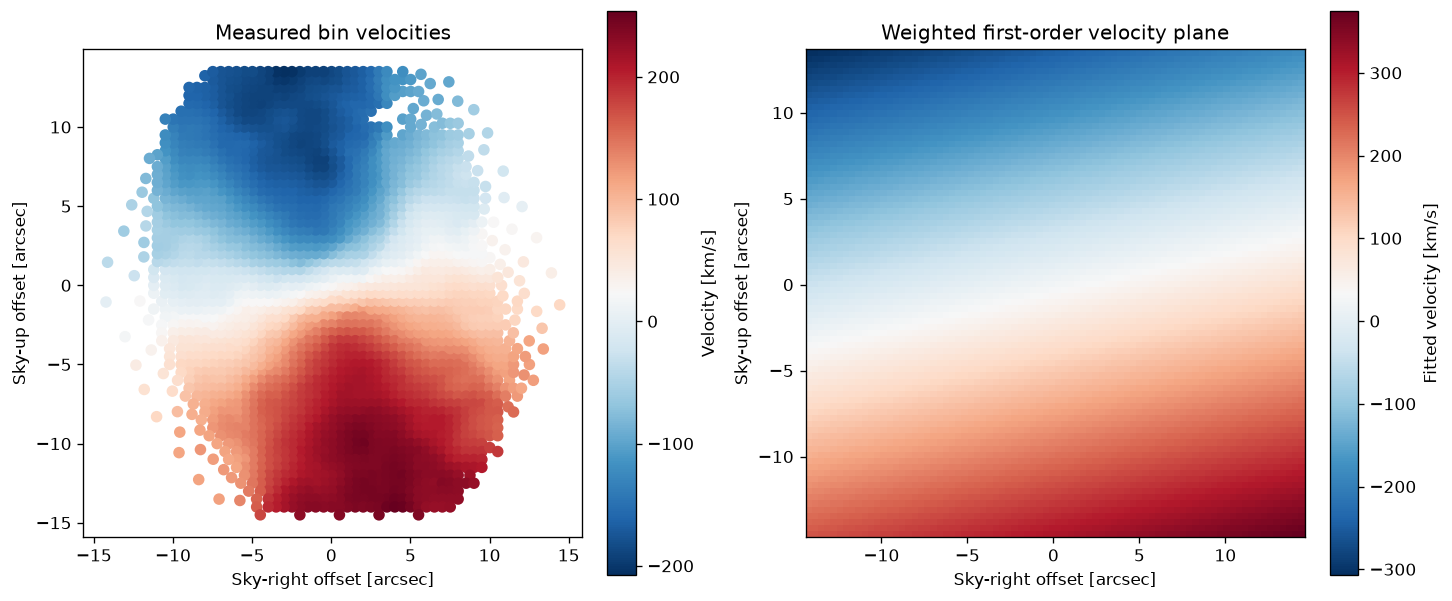

In [9]:
x_grid = np.linspace(np.nanmin(x_bin[fit]), np.nanmax(x_bin[fit]), 80)
y_grid = np.linspace(np.nanmin(y_bin[fit]), np.nanmax(y_bin[fit]), 80)
XX, YY = np.meshgrid(x_grid, y_grid)
VV = a_grad * XX + b_grad * YY + c_fit

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
sc0 = axes[0].scatter(x_bin[fit], y_bin[fit], c=z, cmap="RdBu_r", s=35)
axes[0].set_title("Measured bin velocities")
axes[0].set_xlabel("Sky-right offset [arcsec]")
axes[0].set_ylabel("Sky-up offset [arcsec]")
axes[0].set_aspect("equal")
fig.colorbar(sc0, ax=axes[0], label="Velocity [km/s]")

im = axes[1].pcolormesh(XX, YY, VV, shading="auto", cmap="RdBu_r")
axes[1].set_title("Weighted first-order velocity plane")
axes[1].set_xlabel("Sky-right offset [arcsec]")
axes[1].set_ylabel("Sky-up offset [arcsec]")
axes[1].set_aspect("equal")
fig.colorbar(im, ax=axes[1], label="Fitted velocity [km/s]")
plt.show()

## 10. Estimate a projected rotation amplitude

In [10]:
# A robust percentile-based amplitude; not a dynamical circular speed.
v_low, v_high = np.nanpercentile(v_residual_bin[v_ok], [5, 95])
vrot_projected = 0.5 * (v_high - v_low)
print(f"5th percentile residual velocity: {v_low:.2f} km/s")
print(f"95th percentile residual velocity: {v_high:.2f} km/s")
print(f"Projected rotation amplitude proxy: {vrot_projected:.2f} km/s")
print("This proxy is affected by inclination, radial coverage, beam smearing and binning.")

5th percentile residual velocity: -214.59 km/s
95th percentile residual velocity: 199.08 km/s
Projected rotation amplitude proxy: 206.83 km/s
This proxy is affected by inclination, radial coverage, beam smearing and binning.


## 11. Construct radial profiles in elliptical effective-radius units

In [11]:
# Radial bins from 0 to the largest sampled radius, in units of Re.
r_use = r_re_bin[joint_ok]
v_use = v_residual_bin[joint_ok]
s_use = sigma_bin[joint_ok]
f_use = flux_bin[joint_ok]

r_max = np.nanmax(r_use)
radial_edges = np.arange(0.0, np.ceil(r_max * 2) / 2 + 0.5, 0.5)
if len(radial_edges) < 3:
    radial_edges = np.linspace(0, max(r_max, 1.0), 4)

radial_centers = 0.5 * (radial_edges[:-1] + radial_edges[1:])
v_med_profile = np.full(radial_centers.shape, np.nan)
sigma_med_profile = np.full(radial_centers.shape, np.nan)
n_profile = np.zeros(radial_centers.shape, dtype=int)

for i in range(len(radial_centers)):
    in_bin = (r_use >= radial_edges[i]) & (r_use < radial_edges[i+1])
    n_profile[i] = in_bin.sum()
    if n_profile[i] > 0:
        v_med_profile[i] = np.nanmedian(v_use[in_bin])
        sigma_med_profile[i] = np.nanmedian(s_use[in_bin])

print("Radial bin centers [Re]:", radial_centers)
print("Counts per radial bin:", n_profile)

Radial bin centers [Re]: [0.25 0.75 1.25 1.75]
Counts per radial bin: [ 254  770 1076   94]


## 12. Plot radial velocity and dispersion profiles

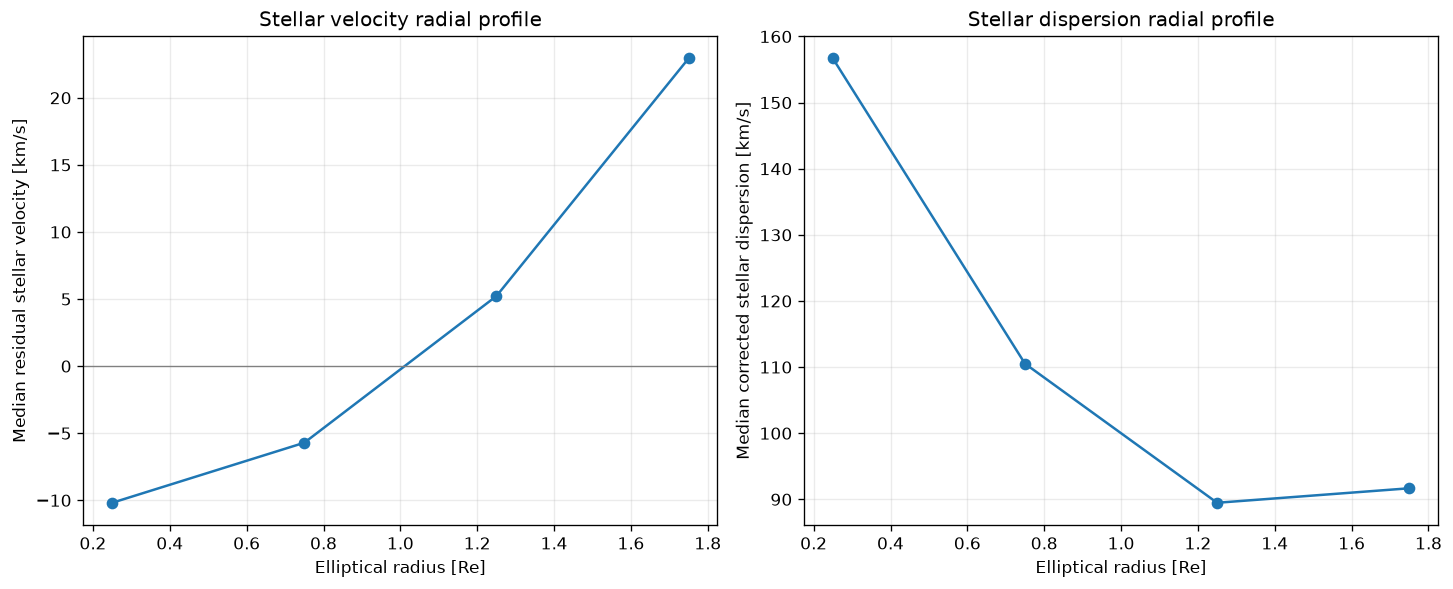

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\stellar_kinematics_radial_profiles.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

axes[0].plot(radial_centers, v_med_profile, marker="o")
axes[0].axhline(0, color="0.5", lw=0.8)
axes[0].set_xlabel("Elliptical radius [Re]")
axes[0].set_ylabel("Median residual stellar velocity [km/s]")
axes[0].set_title("Stellar velocity radial profile")
axes[0].grid(alpha=0.25)

axes[1].plot(radial_centers, sigma_med_profile, marker="o")
axes[1].set_xlabel("Elliptical radius [Re]")
axes[1].set_ylabel("Median corrected stellar dispersion [km/s]")
axes[1].set_title("Stellar dispersion radial profile")
axes[1].grid(alpha=0.25)

profile_path = FIGURES_DIR / "stellar_kinematics_radial_profiles.png"
fig.savefig(profile_path, bbox_inches="tight")
plt.show()
print("Saved:", profile_path)

## 13. Calculate the projected \(\lambda_R\) proxy

We use the commonly adopted luminosity-weighted projected estimator:

\[
\lambda_R =
\frac{\sum_i F_i R_i |V_i|}
{\sum_i F_i R_i \sqrt{V_i^2+\sigma_i^2}}
\]

where:
- \(F_i\) is the positive bin flux proxy,
- \(R_i\) is elliptical radius,
- \(V_i\) is residual line-of-sight velocity,
- \(\sigma_i\) is corrected stellar velocity dispersion.

The sums are cumulative within the specified radius. This is a projected quantity; do not interpret it as intrinsic angular momentum without geometry and inclination corrections.

In [13]:
def calculate_lambda_r(radius, flux, velocity, dispersion, max_radius):
    use = (
        np.isfinite(radius) & np.isfinite(flux) & (flux > 0)
        & np.isfinite(velocity) & np.isfinite(dispersion)
        & (radius <= max_radius)
    )
    if use.sum() == 0:
        return np.nan, 0
    numerator = np.sum(flux[use] * radius[use] * np.abs(velocity[use]))
    denominator = np.sum(
        flux[use] * radius[use]
        * np.sqrt(velocity[use]**2 + dispersion[use]**2)
    )
    return (numerator / denominator if denominator > 0 else np.nan), int(use.sum())

lambda_r_1re, n_1re = calculate_lambda_r(
    r_use, f_use, v_use, s_use, 1.0
)
lambda_r_2re, n_2re = calculate_lambda_r(
    r_use, f_use, v_use, s_use, 2.0
)
print(f"lambda_R within 1 Re: {lambda_r_1re:.4f} (N bins={n_1re})")
print(f"lambda_R within 2 Re: {lambda_r_2re:.4f} (N bins={n_2re})")

lambda_R within 1 Re: 0.6462 (N bins=1024)
lambda_R within 2 Re: 0.7156 (N bins=2194)


## 14. Plot cumulative lambda_R as a function of radius

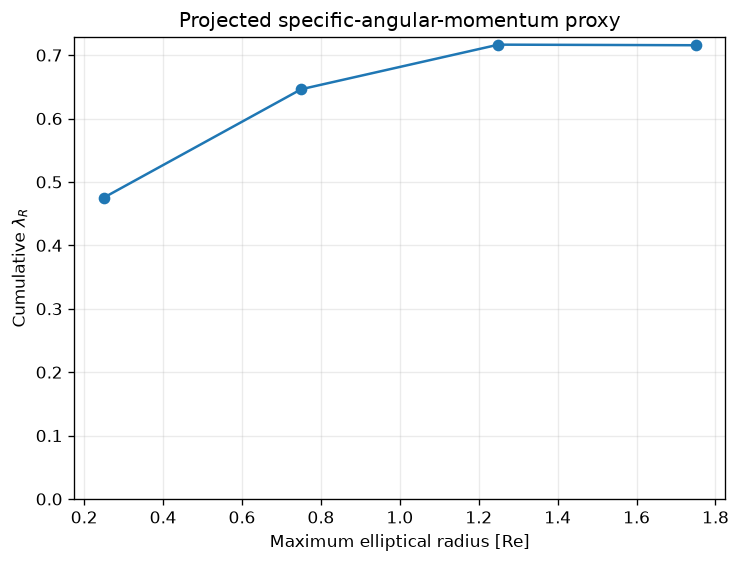

Saved: D:\KS\manga-stellar-kinematics\outputs\figures\lambda_R_cumulative_profile.png


In [14]:
lambda_r_profile = np.full(radial_centers.shape, np.nan)
lambda_n_profile = np.zeros(radial_centers.shape, dtype=int)

for i, radius in enumerate(radial_edges[1:]):
    lambda_r_profile[i], lambda_n_profile[i] = calculate_lambda_r(
        r_use, f_use, v_use, s_use, radius
    )

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(radial_centers, lambda_r_profile, marker="o")
ax.set_xlabel("Maximum elliptical radius [Re]")
ax.set_ylabel(r"Cumulative $\lambda_R$")
ax.set_title(r"Projected specific-angular-momentum proxy")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
lambda_path = FIGURES_DIR / "lambda_R_cumulative_profile.png"
fig.savefig(lambda_path, bbox_inches="tight")
plt.show()
print("Saved:", lambda_path)

## 15. Save quantitative measurements and radial profiles

In [15]:
summary_path = OUTPUT_DIR / "stellar_kinematics_quantitative_summary.txt"
summary = [
    "MaNGA Stellar Kinematics Quantitative Summary",
    "Plate-IFU: 8138-12704",
    "DAPTYPE: HYB10-MILESHC-MASTARSSP",
    f"Unique stellar bins: {len(unique_bin_ids)}",
    f"Valid velocity bins: {v_ok.sum()}",
    f"Valid corrected-dispersion bins: {sigma_ok.sum()}",
    f"Joint valid bins: {joint_ok.sum()}",
    f"Residual systemic velocity estimate [km/s]: {v_sys_residual:.4f}",
    f"Robust velocity scatter [km/s]: {v_scatter:.4f}",
    f"First-order kinematic PA [deg, N through E, modulo 180]: {pa_axis_deg:.4f}",
    f"Velocity gradient amplitude [km/s/arcsec]: {gradient_amplitude:.4f}",
    f"Projected rotation amplitude proxy [km/s]: {vrot_projected:.4f}",
    f"lambda_R within 1 Re: {lambda_r_1re:.5f}",
    f"lambda_R within 2 Re: {lambda_r_2re:.5f}",
    "Caution: these are first-pass projected estimates, not deprojected dynamical quantities."
]
summary_path.write_text("\n".join(summary), encoding="utf-8")
print(summary_path.read_text(encoding="utf-8"))

profile_path_csv = OUTPUT_DIR / "stellar_kinematics_radial_profiles.csv"
profile_data = np.column_stack([
    radial_edges[:-1], radial_edges[1:], radial_centers,
    n_profile, v_med_profile, sigma_med_profile,
    lambda_r_profile, lambda_n_profile
])
np.savetxt(
    profile_path_csv, profile_data, delimiter=",",
    header="r_inner_Re,r_outer_Re,r_center_Re,n_bins,median_v_kms,median_sigma_kms,cumulative_lambda_R,n_lambda_bins",
    comments=""
)
print("Saved radial profiles:", profile_path_csv)

MaNGA Stellar Kinematics Quantitative Summary
Plate-IFU: 8138-12704
DAPTYPE: HYB10-MILESHC-MASTARSSP
Unique stellar bins: 2194
Valid velocity bins: 2194
Valid corrected-dispersion bins: 2194
Joint valid bins: 2194
Residual systemic velocity estimate [km/s]: 33.6441
Robust velocity scatter [km/s]: 190.3056
First-order kinematic PA [deg, N through E, modulo 180]: 167.3003
Velocity gradient amplitude [km/s/arcsec]: 20.2767
Projected rotation amplitude proxy [km/s]: 206.8342
lambda_R within 1 Re: 0.64621
lambda_R within 2 Re: 0.71560
Caution: these are first-pass projected estimates, not deprojected dynamical quantities.
Saved radial profiles: D:\KS\manga-stellar-kinematics\outputs\stellar_kinematics_radial_profiles.csv


## 16. Close files

In [16]:
maps.close()
kin.close()
print("MAPS FITS and NPZ files closed.")

MAPS FITS and NPZ files closed.


## 17. Milestone 5 checklist

- [ ] One representative sample per stellar kinematic bin selected.
- [ ] DAP masks and inverse variances applied.
- [ ] Residual systemic velocity estimated relative to the input guess redshift.
- [ ] First-order velocity-plane fit inspected.
- [ ] Kinematic PA estimate checked against the velocity map.
- [ ] Projected rotation amplitude proxy calculated.
- [ ] Radial velocity and dispersion profiles plotted.
- [ ] Cumulative \(\lambda_R\) calculated and plotted.
- [ ] Summary and radial profile files saved.

### Before interpreting results
Compare the fitted PA with the visual velocity gradient. Check whether the field is regular, whether radial coverage is adequate, and whether the strict mask leaves enough bins. The DAP's photometric elliptical coordinates are inherited from the adopted photometric geometry; they are not a fresh kinematic deprojection.

A stellar velocity field or \(\lambda_R\) measurement by itself does **not** demonstrate a supermassive-black-hole binary. That scientific claim needs independent evidence and a model that accounts for spatial resolution, dynamical structure, and observational uncertainties.

**Next milestone:** scientific interpretation, uncertainty/systematics checks, and a reproducible report connecting the measurements to the candidate host-galaxy research question.